<a href="https://colab.research.google.com/github/nyarotoyi/loan_prediction/blob/main/loan_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[link text](https:// [link text](https://))# Loan Prediction Project

Name : Marice Ziana Otoyi

Course : Msc Artificial Intelligence

Reg: GMAI/ON/4355/09/26

Email : motoyi@kabarak.ac.ke

Practical 1



Follows the tutorial [here](https://www.analyticsvidhya.com/blog/2022/05/loan-prediction-problem-from-scratch-to-end/)

This project addresses a **binary classification problem** using supervised machine learning. The goal is to predict whether a loan application will be approved or not based on applicant information. The dataset is loaded directly from Kaggle using **KaggleHub**.

The project follows these main steps:

## 1. Problem Understanding

Dream Housing Finance Company provides home loans to customers in urban, semi-urban, and rural areas. Customers apply for loans by providing information such as gender, marital status, education level, number of dependents, income, loan amount, loan term, credit history, and property area.

The company wants to automate the loan eligibility process so that it can determine whether an applicant is likely to qualify for a loan based on the information provided during the application process.

The objective of this project is therefore to build a machine learning model that can predict **Loan_Status**, where the outcome belongs to one of two classes:

- **Y** — Loan approved
- **N** — Loan not approved

Because the target variable has two possible outcomes, this is a **binary classification problem**.

## 2. Hypothesis Generation

Before examining the data, we generate hypotheses about factors that may influence loan approval. These are initial assumptions that will later be tested through exploratory data analysis.

Some possible factors include:

- **Applicant income:** Applicants with higher incomes may have a greater chance of loan approval.
- **Credit history:** Applicants with a positive repayment history may be more likely to receive approval.
- **Loan amount:** Applicants requesting smaller loan amounts may have a higher chance of approval.
- **Loan term:** The length of the repayment period may influence the approval decision.
- **Repayment burden:** Applicants whose expected loan repayments are lower relative to their income may have a greater chance of approval.
- **Co-applicant income:** Additional household income may improve an applicant's ability to repay the loan.

These are hypotheses rather than conclusions and will be examined against the available data.

## 3. Environment Setup and Data Loading

The required Python libraries are installed and imported. The training and test datasets are loaded directly from Kaggle using KaggleHub and stored as Pandas DataFrames.

## 4. Understanding the Data

The structure of the training and test datasets is examined, including:

- Dataset dimensions
- Column names
- Data types
- Target variable
- Missing values
- Categorical and numerical variables

## 5. Exploratory Data Analysis

The dataset is explored using descriptive statistics and visualizations to understand:

- The distribution of the target variable
- Individual variable distributions
- Relationships between variables and loan approval
- Possible outliers and skewed variables
- Patterns that may support or contradict the initial hypotheses

## 6. Data Preprocessing

The data is prepared for machine learning by addressing issues such as:

- Missing values
- Categorical variable encoding
- Outliers
- Variable transformations
- Feature preparation

## 7. Model Building

Classification algorithms are trained using the prepared training data to learn the relationship between applicant characteristics and loan approval.

## 8. Model Evaluation

The performance of the models is evaluated using appropriate classification metrics and validation techniques.

## 9. Feature Engineering and Model Improvement

Additional features may be created from existing variables to better represent factors such as household income and repayment burden. Model performance is then compared after introducing these features.

## 10. Final Prediction

The selected model is used to predict loan approval outcomes for the test dataset.

## Environment Setup
We first install the packages needed for our analysis. KaggleHub’s Pandas support allows us to load the Kaggle dataset directly into DataFrames. We also install Scikit-learn and XGBoost for modelling, and Seaborn for visualisation. The `-q` option reduces installation messages to keep the notebook output tidy.


In [ ]:
%pip install -q "kagglehub[pandas-datasets]" xgboost scikit-learn seaborn
 # Install KaggleHub with support for loading datasets directly into Pandas

# Import Libraries
We import all the libraries and frameworks we will be using in the model

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter
from IPython.display import display
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from xgboost import XGBClassifier
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
OUTPUT_DIR = Path("loan_predictions")
OUTPUT_DIR.mkdir(exist_ok=True)


# Load the Data
Since we are loading our dataset directly from kaggle, we will load it using the kagglehub library and save it as a pandas dataframes.

In [ ]:
# Load the training dataset from Kaggle into a Pandas DataFrame
train = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,  # Return the file as a Pandas DataFrame
    "altruistdelhite04/loan-prediction-problem-dataset",  # Kaggle dataset name
    "train_u6lujuX_CVtuZ9i.csv"  # Training file
)

# Load the test dataset from Kaggle into a Pandas DataFrame
test = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,  # Return the file as a Pandas DataFrame
    "altruistdelhite04/loan-prediction-problem-dataset",  # Same Kaggle dataset
    "test_Y3wMUE5_7gLdaTN.csv"  # Test file
)

/tmp/ipykernel_443/892401117.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  train = kagglehub.load_dataset(


Using Colab cache for faster access to the 'loan-prediction-problem-dataset' dataset.


/tmp/ipykernel_443/892401117.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  test = kagglehub.load_dataset(


Using Colab cache for faster access to the 'loan-prediction-problem-dataset' dataset.


# Understanding the Data

Before analysing the data, we examine the first few rows, column names, data types, and dimensions to understand how the datasets are structured.

We also review summary statistics to identify typical values, variation, and possible extreme values. This helps us determine how to explore and prepare each variable for modelling.

We also create copies of both datasets to preserve the original data before making any changes.


In [ ]:
# Show the first five rows of the training dataset
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
# Show the first five rows of the test dataset
test.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [ ]:
# Create a copy of the training dataset before making any changes
train_original = train.copy()

# Create a copy of the test dataset before making any changes
test_original = test.copy()

In [ ]:
# Display all column names in the training dataset
train.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [ ]:
# Display all column names in the test dataset
test.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='object')

# Check the data types of each column
We are trying to understand the dataset.

For us to perform the training, we need need the values to be numerical, We check the data types so that we get to encode the categorical variables into numerical representations.



In [ ]:
# Display the data type of each column in the training dataset
train.dtypes

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


# Check the dimensions of the datasets

We need to understand how many values we are working with, The columns, and the rows(Observations).

We expect a one-column difference because the training data includes Loan_Status, while the test data does not.


In [ ]:
# Display the number of rows and columns in the training dataset
print("Training data shape:", train.shape)

# Display the number of rows and columns in the test dataset
print("Test data shape:", test.shape)

Training data shape: (614, 13)
Test data shape: (367, 12)


# Descriptive statistics
before plotting anything, we want a quick statistical summary of the scale, spread, missingness, and possible extreme values in our dataset.

In [ ]:
# Generate descriptive statistics for the numerical columns
train.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [ ]:
# Generate descriptive statistics for categorical columns
train.describe(include='object')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


# Univariate Analysis
Next we analyze our target variable [Loan_Status], since it is a categorical datatype through visualizations  and statistics to understand its distribution and behavior.

First, count the number of approved and rejected applications

In [ ]:
# Count the number of observations in each loan status category
train['Loan_Status'].value_counts()

,count
Loan_Status,
Y,422
N,192


We observe that 422 loan applications were approved and 192 were rejected.

In [ ]:
# Calculate the proportion of each loan status category
train['Loan_Status'].value_counts(normalize=True)
# normalize=True converts the counts into proportions.

,proportion
Loan_Status,
Y,0.687296
N,0.312704


 Approved applications account for approximately 69% of the dataset, indicating an imbalance between the two classes. A model that always predicts approval would therefore achieve about 69% accuracy, giving us a baseline against which to assess our models.

We now visualise the proportion of approved and rejected applications using a bar chart. Setting `normalize=True` converts the counts into proportions, making it easier to compare the two classes and see the imbalance in our target variable.

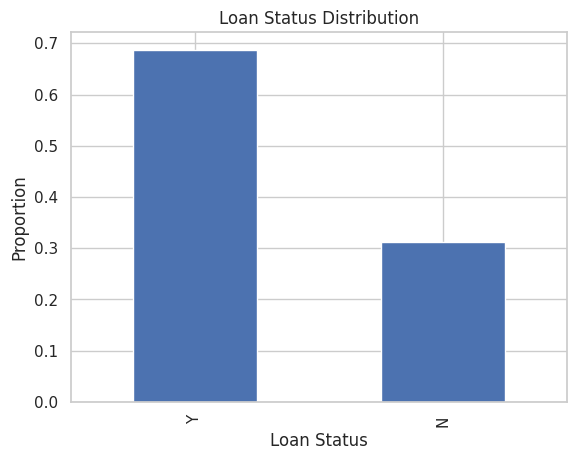

In [ ]:
# Plot the proportion of approved and rejected loan applications
train['Loan_Status'].value_counts(normalize=True).plot.bar()

# Add a title
plt.title('Loan Status Distribution')

# Label the x-axis
plt.xlabel('Loan Status')

# Label the y-axis
plt.ylabel('Proportion')

# Display the plot
plt.show()

The training dataset contains more approved loan applications than rejected applications.

# Univariate analysis of categorical variables


Gender
Gender
Male      0.813644
Female    0.186356
Name: proportion, dtype: float64


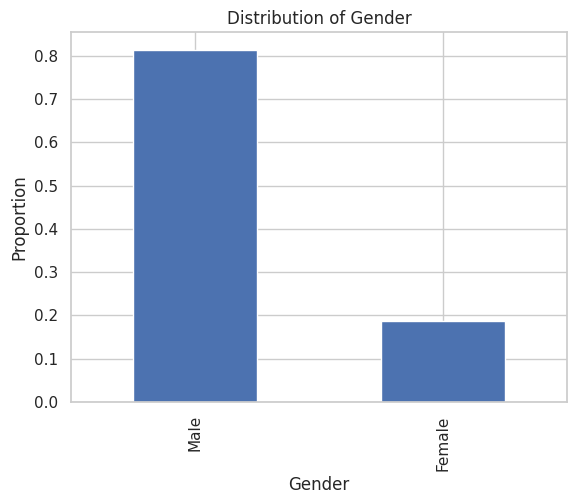


Married
Married
Yes    0.651391
No     0.348609
Name: proportion, dtype: float64


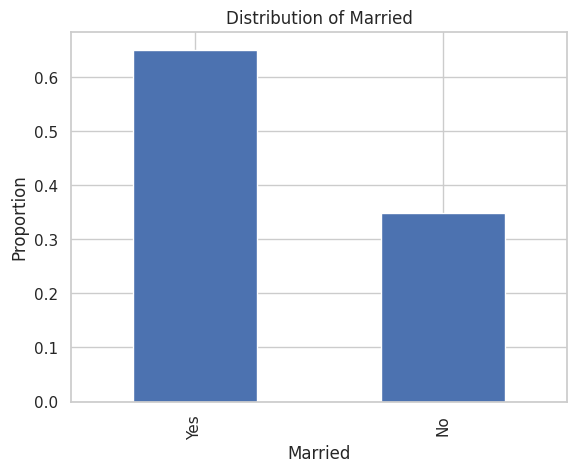


Self_Employed
Self_Employed
No     0.859107
Yes    0.140893
Name: proportion, dtype: float64


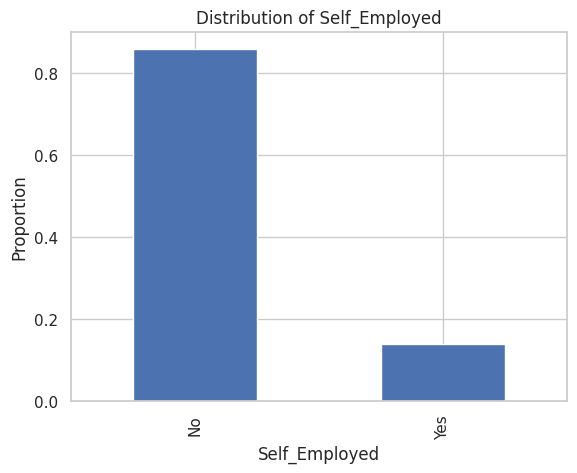


Credit_History
Credit_History
1.0    0.842199
0.0    0.157801
Name: proportion, dtype: float64


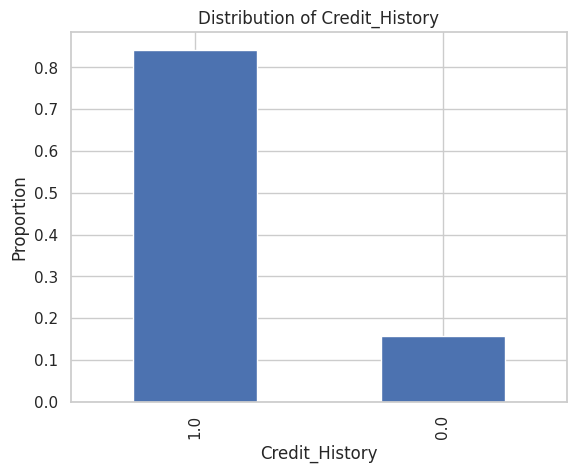


Dependents
Dependents
0     0.575960
1     0.170284
2     0.168614
3+    0.085142
Name: proportion, dtype: float64


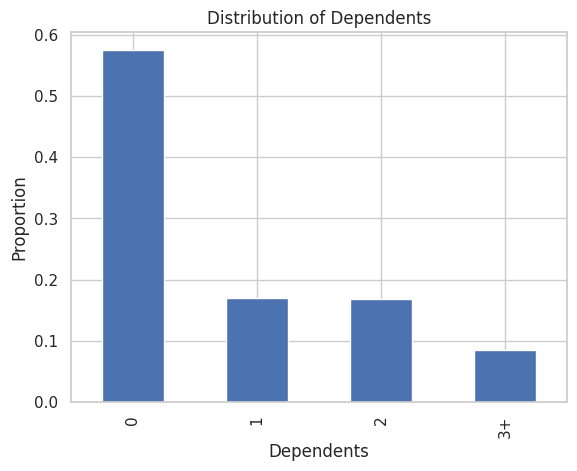


Education
Education
Graduate        0.781759
Not Graduate    0.218241
Name: proportion, dtype: float64


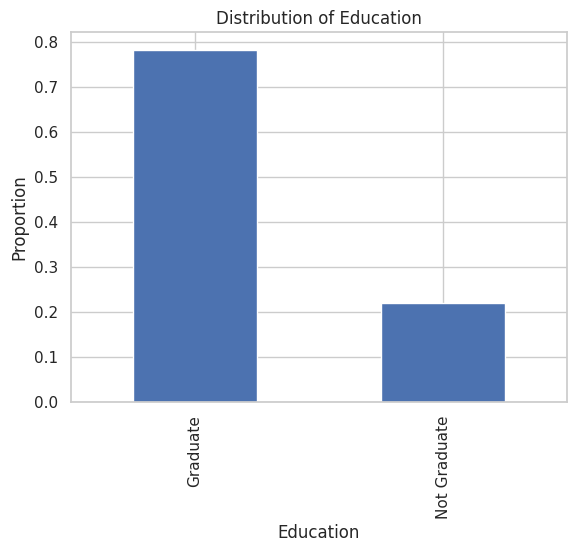


Property_Area
Property_Area
Semiurban    0.379479
Urban        0.328990
Rural        0.291531
Name: proportion, dtype: float64


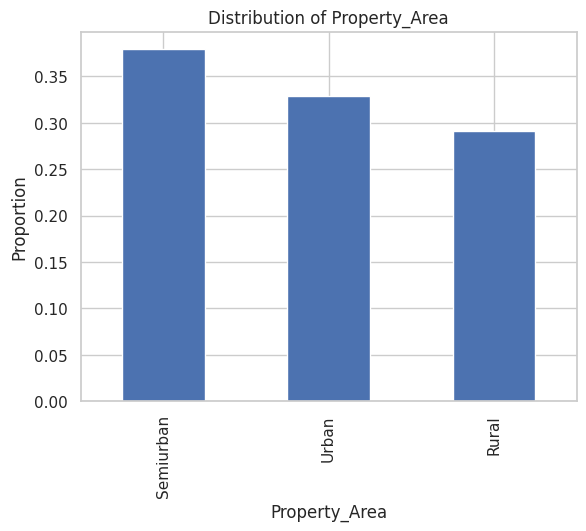

In [ ]:
# List the categorical variables we want to examine
categorical_vars = [
    'Gender',
    'Married',
    'Self_Employed',
    'Credit_History',
    'Dependents',
    'Education',
    'Property_Area'
]

# Loop through each categorical variable
for column in categorical_vars:

    # Print the variable name so we know which output we are looking at
    print(f"\n{column}")

    # Display the proportion of observations in each category
    print(train[column].value_counts(normalize=True))

    # Plot the distribution of the categories
    train[column].value_counts(normalize=True).plot.bar()

    # Add a descriptive title to the chart
    plt.title(f'Distribution of {column}')

    # Label the horizontal axis with the variable name
    plt.xlabel(column)

    # Label the vertical axis as proportion
    plt.ylabel('Proportion')

    # Display the current chart
    plt.show()

From our univariate visualization of the categorical predictors, we observe the following characteristics of the applicant pool:

* **Gender:** Overwhelmingly male (~81%).
* **Marital Status:** Most applicants are married (~65%).
* **Dependents:** The majority (~57%) of applicants have 0 dependents.
* **Self-Employment:** Only a small fraction (~14%) are self-employed.
* **Education:** A large majority (~78%) are Graduates.
* **Property Area:** Semiurban is the most common region (~38%), followed closely by Urban and Rural.

# Univariate analysis of numerical variables
Since numerical values can have many distinct values, we will not look at bar charts but rather,
- the distribution,
- the center,
- the spread,
- skewness,
- possible outliers.


ApplicantIncome
count      614.000000
mean      5403.459283
std       6109.041673
min        150.000000
25%       2877.500000
50%       3812.500000
75%       5795.000000
max      81000.000000
Name: ApplicantIncome, dtype: float64


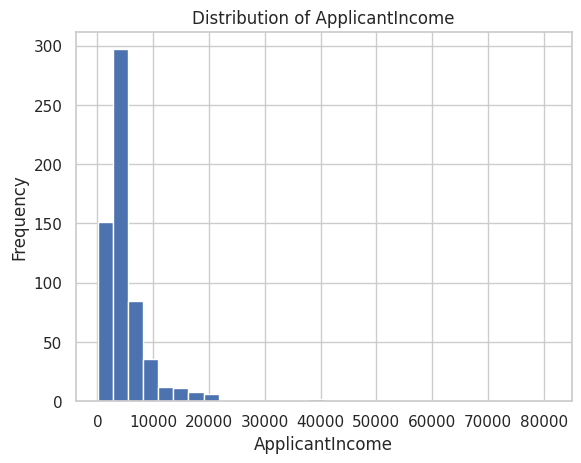

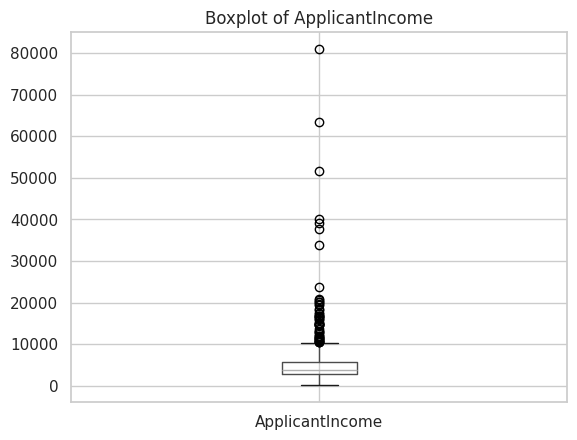


CoapplicantIncome
count      614.000000
mean      1621.245798
std       2926.248369
min          0.000000
25%          0.000000
50%       1188.500000
75%       2297.250000
max      41667.000000
Name: CoapplicantIncome, dtype: float64


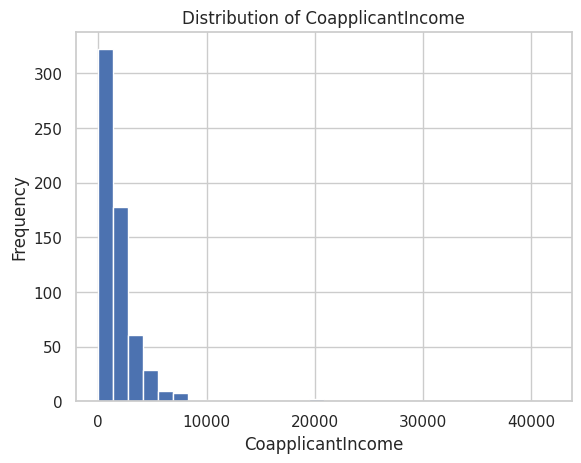

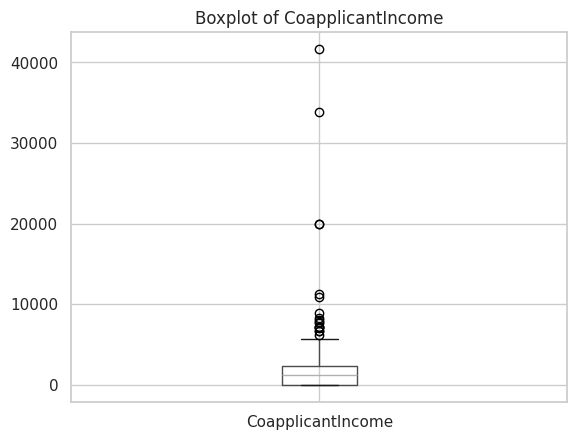


LoanAmount
count    592.000000
mean     146.412162
std       85.587325
min        9.000000
25%      100.000000
50%      128.000000
75%      168.000000
max      700.000000
Name: LoanAmount, dtype: float64


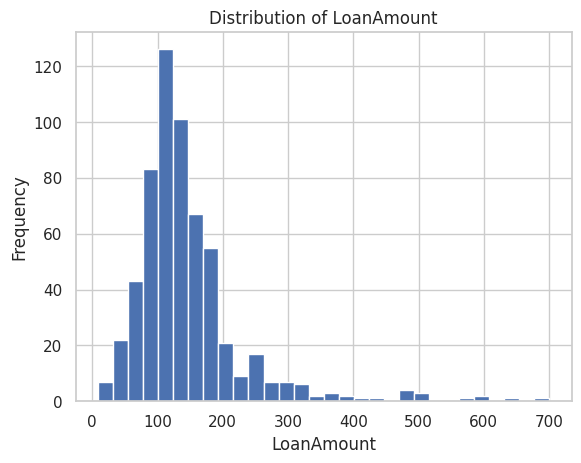

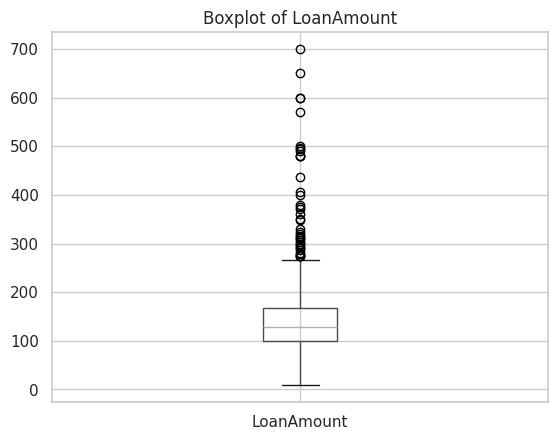


Loan_Amount_Term
count    600.00000
mean     342.00000
std       65.12041
min       12.00000
25%      360.00000
50%      360.00000
75%      360.00000
max      480.00000
Name: Loan_Amount_Term, dtype: float64


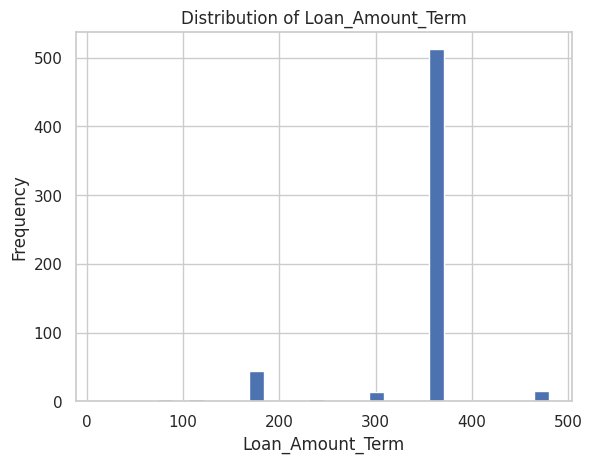

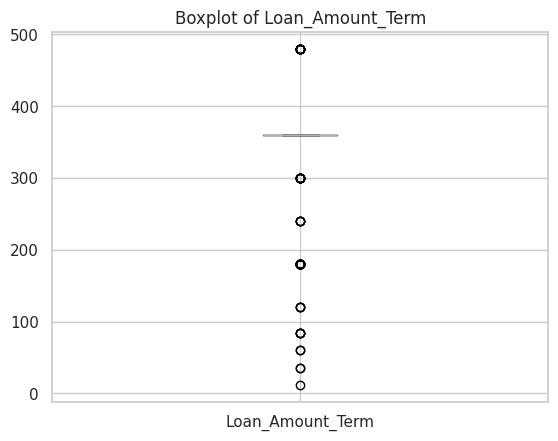

In [ ]:
# List the numerical variables we want to examine
numerical_vars = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

# Loop through each numerical variable
for column in numerical_vars:

    # Print the variable name
    print(f"\n{column}")

    # Display descriptive statistics for the variable
    print(train[column].describe())

    # Plot a histogram to show the distribution of values
    train[column].hist(bins=30)

    # Add a descriptive title
    plt.title(f'Distribution of {column}')

    # Label the horizontal axis
    plt.xlabel(column)

    # Label the vertical axis
    plt.ylabel('Frequency')

    # Display the histogram
    plt.show()

    # Create a boxplot to help identify possible outliers
    train.boxplot(column=column)

    # Add a title
    plt.title(f'Boxplot of {column}')

    # Display the boxplot
    plt.show()

- *ApplicantIncome:* The distribution is right-skewed, with a few very high-income applicants pulling the mean above the median.
- *CoapplicantIncome:* Also right-skewed, with many applicants reporting zero coapplicant income and a few very high values.
- *LoanAmount:* Contains 22 missing values and shows some right-skewness, with a few unusually large loan amounts.
- *Loan_Amount_Term:* Contains 14 missing values and is heavily concentrated around 360 months, suggesting most applicants have similar repayment periods.

# Bivariate analysis
we examine how each predictor relates to Loan_Status.
We get to test our hypotheses using bivariate analysis


Gender
Loan_Status         N         Y
Gender                         
Female       0.330357  0.669643
Male         0.306748  0.693252


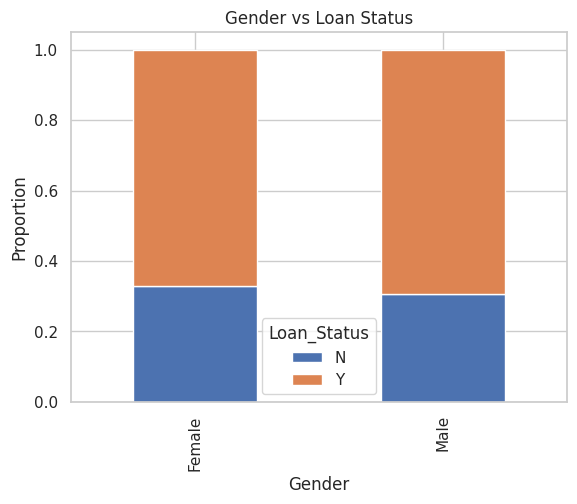


Married
Loan_Status         N         Y
Married                        
No           0.370892  0.629108
Yes          0.283920  0.716080


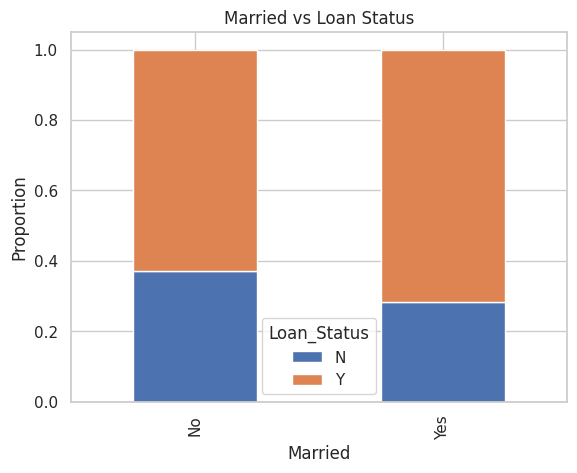


Dependents
Loan_Status         N         Y
Dependents                     
0            0.310145  0.689855
1            0.352941  0.647059
2            0.247525  0.752475
3+           0.352941  0.647059


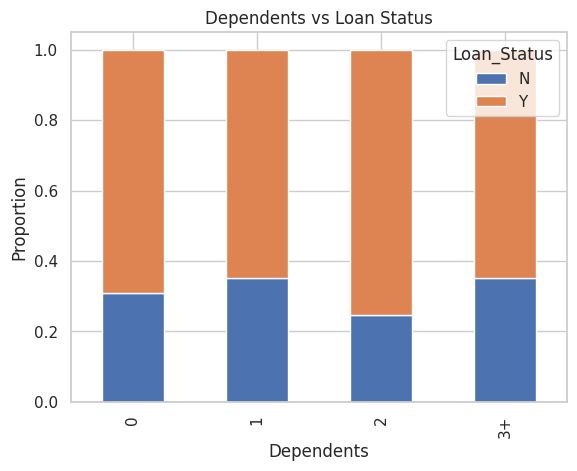


Education
Loan_Status          N         Y
Education                       
Graduate      0.291667  0.708333
Not Graduate  0.388060  0.611940


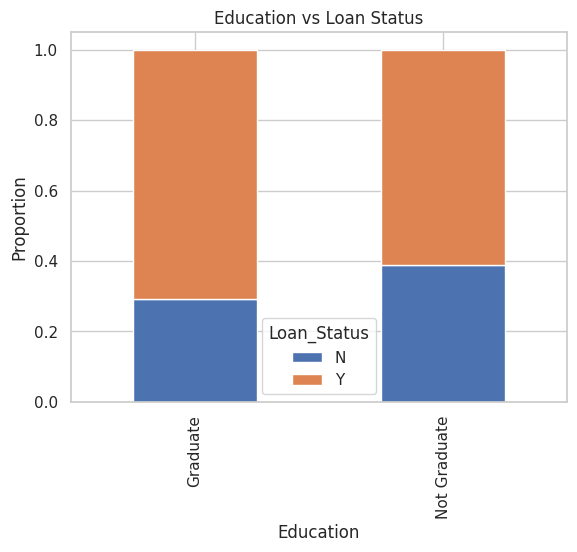


Self_Employed
Loan_Status           N         Y
Self_Employed                    
No             0.314000  0.686000
Yes            0.317073  0.682927


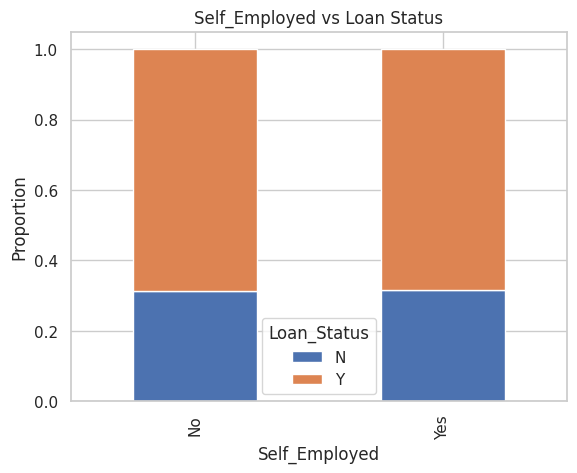


Credit_History
Loan_Status            N         Y
Credit_History                    
0.0             0.921348  0.078652
1.0             0.204211  0.795789


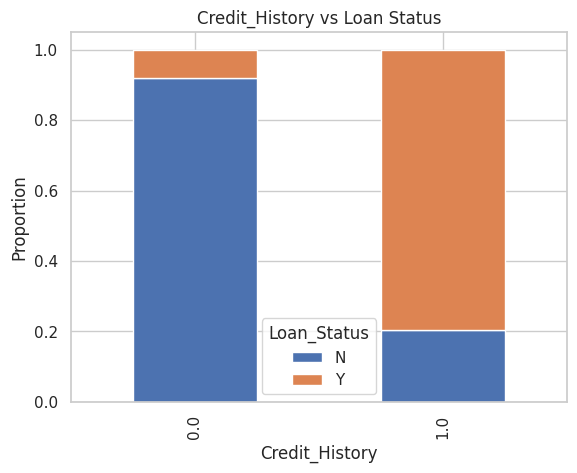


Property_Area
Loan_Status           N         Y
Property_Area                    
Rural          0.385475  0.614525
Semiurban      0.231760  0.768240
Urban          0.341584  0.658416


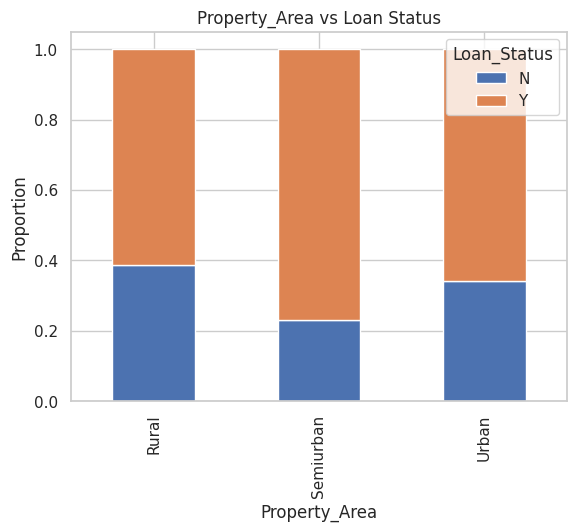

In [ ]:
# List categorical variables to compare with Loan_Status
categorical_vars = [
    'Gender',
    'Married',
    'Dependents',
    'Education',
    'Self_Employed',
    'Credit_History',
    'Property_Area'
]

# Loop through each categorical variable
for column in categorical_vars:

    # Create a cross-tab showing proportions of approved and rejected loans
    comparison = pd.crosstab(
        train[column],                 # Predictor variable
        train['Loan_Status'],          # Target variable
        normalize='index'              # Convert counts into row-wise proportions
    )

    # Print the proportion table
    print(f"\n{column}")
    print(comparison)

    # Plot the proportions as a stacked bar chart
    comparison.plot(kind='bar', stacked=True)

    # Add chart title
    plt.title(f'{column} vs Loan Status')

    # Label the axes
    plt.xlabel(column)
    plt.ylabel('Proportion')

    # Display the chart
    plt.show()

- **Gender:** Approval rates are similar for male and female applicants, suggesting little visible difference by gender.
- **Marital Status:** Married applicants show a higher approval rate than unmarried applicants.
- **Dependents:** Applicants with two dependents have the highest approval rate, while those with one or three-plus dependents have lower rates.
- **Education:** Graduates have a higher approval rate than non-graduates.
- **Self-Employment:** Approval rates are almost identical for self-employed and non-self-employed applicants, suggesting little visible association.
- **Credit History:** This shows the strongest pattern. Applicants with a positive credit history have a much higher approval rate than those without one.
- **Property Area:** Applicants from semi-urban areas have the highest approval rate, followed by urban and then rural applicants.

We consider this not as evidence of causation.but as associations.

For numerical predictors, comparing group averages and distributions is more useful than stacked bar charts.


ApplicantIncome
Loan_Status
N    5446.078125
Y    5384.068720
Name: ApplicantIncome, dtype: float64


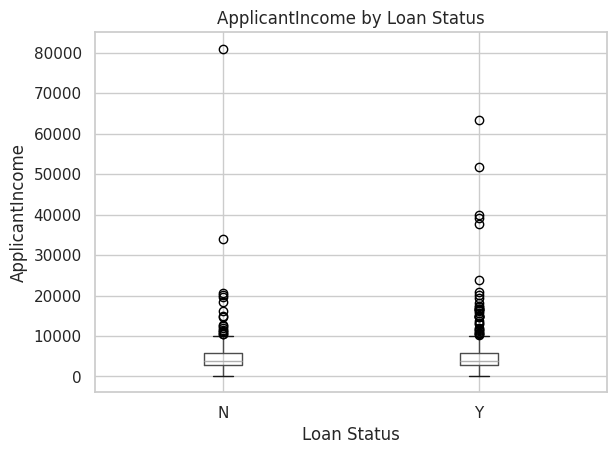


CoapplicantIncome
Loan_Status
N    1877.807292
Y    1504.516398
Name: CoapplicantIncome, dtype: float64


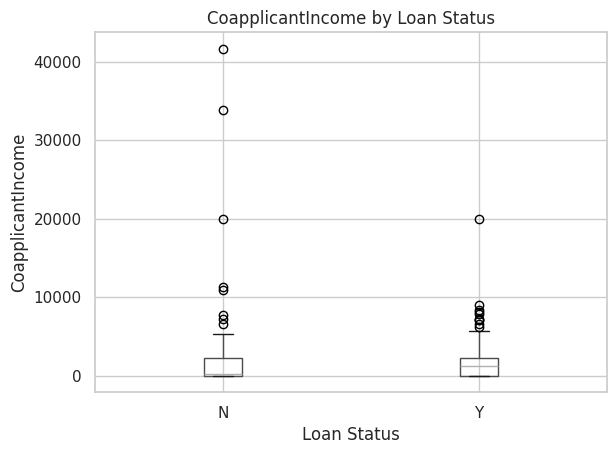


LoanAmount
Loan_Status
N    151.220994
Y    144.294404
Name: LoanAmount, dtype: float64


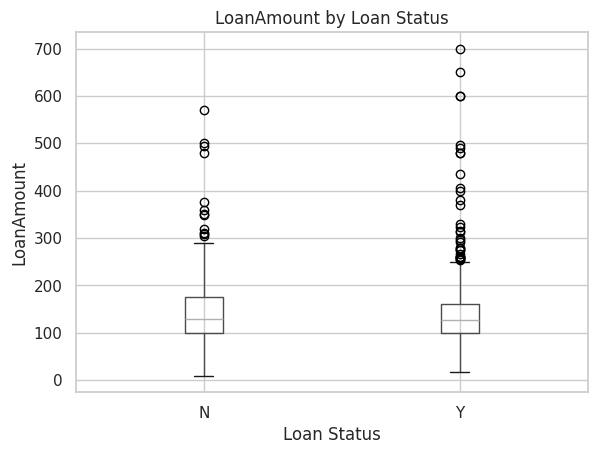


Loan_Amount_Term
Loan_Status
N    344.064516
Y    341.072464
Name: Loan_Amount_Term, dtype: float64


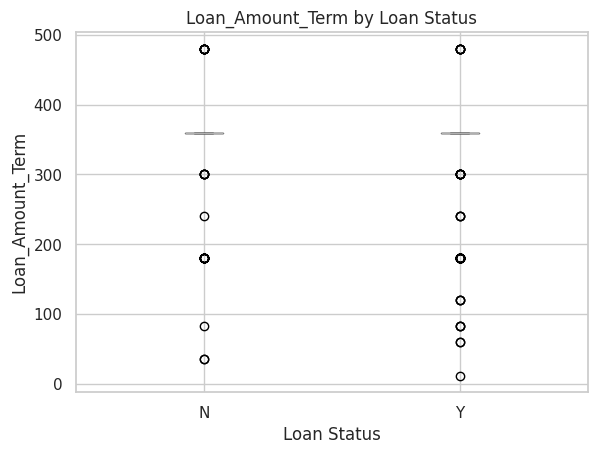

In [ ]:
# List the numerical variables to compare with Loan_Status
numerical_vars = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

# Loop through each numerical variable
for column in numerical_vars:

    # Display the average value for approved and rejected loan applications
    print(f"\n{column}")
    print(train.groupby('Loan_Status')[column].mean())

    # Create a boxplot to compare the distribution across loan status groups
    train.boxplot(column=column, by='Loan_Status')

    # Add a descriptive title
    plt.title(f'{column} by Loan Status')

    # Remove the automatic overall title added by Pandas
    plt.suptitle('')

    # Label the axes
    plt.xlabel('Loan Status')
    plt.ylabel(column)

    # Display the chart
    plt.show()

Analyzing the bivariate relationship of numerical variables with `Loan_Status` reveals several key insights:

* **ApplicantIncome & CoapplicantIncome:** Individual raw incomes exhibit remarkably similar group averages between approved and rejected applications. This suggests that looking at individual raw incomes in isolation does not strongly differentiate loan approval status.
* **LoanAmount:** Rejected applicants request slightly higher loan amounts on average than those who are approved.
* **Loan_Amount_Term:** The average repayment period is virtually identical across both categories, heavily concentrated at the 360-month (30-year) mark.

These findings suggest that individual raw numerical features have weak linear separating boundaries on their own, highlighting the need for joint feature engineering (such as combining household incomes and calculating installment-to-income buffers).

# Correlation analysis for numerical variables.

This helps us see how strongly the numerical features move together.

Correlation measures the strength and direction of a linear relationship between two numerical variables.

Values range from:
-1  → strong negative relationship

 0  → little or no linear relationship

+1  → strong positive relationship

For example:
- positive correlation: as one variable increases, the other tends to increase
- negative correlation: as one increases, the other tends to decrease

In [ ]:
# Select only the numerical columns from the training dataset
numerical_data = train.select_dtypes(include=['int64', 'float64'])

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Display the correlation values
correlation_matrix

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
ApplicantIncome,1.000000,-0.116605,0.570909,-0.045306,-0.014715
CoapplicantIncome,-0.116605,1.000000,0.188619,-0.059878,-0.002056
LoanAmount,0.570909,0.188619,1.000000,0.039447,-0.008433
Loan_Amount_Term,-0.045306,-0.059878,0.039447,1.000000,0.001470
Credit_History,-0.014715,-0.002056,-0.008433,0.001470,1.000000


Our correlation heatmap reveals that **`ApplicantIncome`** and **`LoanAmount`** have a moderate positive correlation ($r \approx 0.57$). This aligns with economic intuition: applicants with higher incomes apply for larger loans. Other features show very low correlation with each other, meaning they represent mostly independent dimensions of applicant profiles.

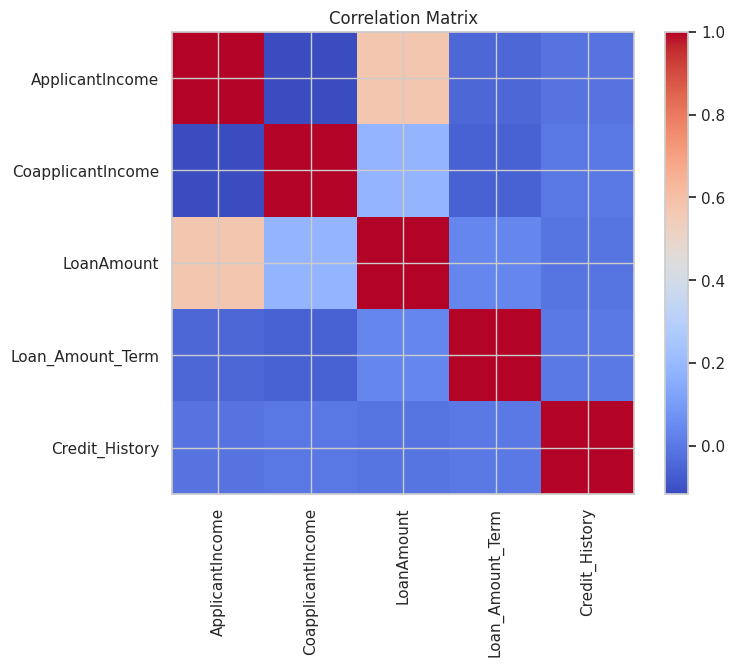

In [ ]:
# Create a heatmap-style visualization of the correlation matrix
plt.figure(figsize=(8, 6))

# Display the correlation matrix as an image
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='nearest')

# Add a color scale
plt.colorbar()

# Add variable names to the x-axis
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

# Add variable names to the y-axis
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

# Add a title
plt.title('Correlation Matrix')

# Display the plot
plt.show()


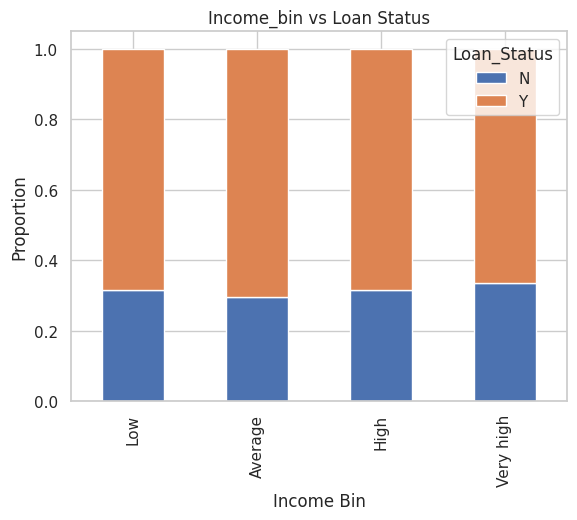

Non-missing values outside bins: 0


In [ ]:
train["Income_bin"] = pd.cut(train["ApplicantIncome"], bins=[0, 2500, 4000, 6000, 81000],
                              labels=['Low', 'Average', 'High', 'Very high'], include_lowest=True)


comparison_income = pd.crosstab(train["Income_bin"], train['Loan_Status'], normalize='index')
comparison_income.plot(kind='bar', stacked=True)
plt.title('Income_bin vs Loan Status')
plt.xlabel('Income Bin')
plt.ylabel('Proportion')
plt.show()

print("Non-missing values outside bins:", int((train["ApplicantIncome"].notna() & train["Income_bin"].isna()).sum()))

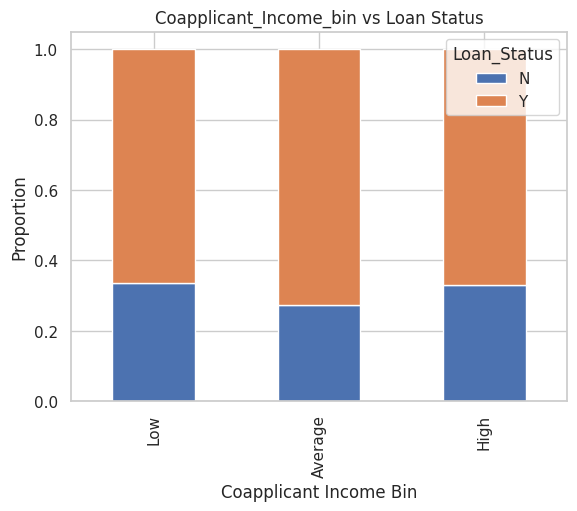

Non-missing values outside bins: 0


In [ ]:
train["Coapplicant_Income_bin"] = pd.cut(train["CoapplicantIncome"], bins=[0, 1000, 3000, 42000],
                              labels=['Low', 'Average', 'High'], include_lowest=True)

comparison_coapplicant = pd.crosstab(train["Coapplicant_Income_bin"], train['Loan_Status'], normalize='index')
comparison_coapplicant.plot(kind='bar', stacked=True)
plt.title('Coapplicant_Income_bin vs Loan Status')
plt.xlabel('Coapplicant Income Bin')
plt.ylabel('Proportion')
plt.show()

print("Non-missing values outside bins:", int((train["CoapplicantIncome"].notna() & train["Coapplicant_Income_bin"].isna()).sum()))

In [ ]:
train["Total_Income"] = train["ApplicantIncome"] + train["CoapplicantIncome"]


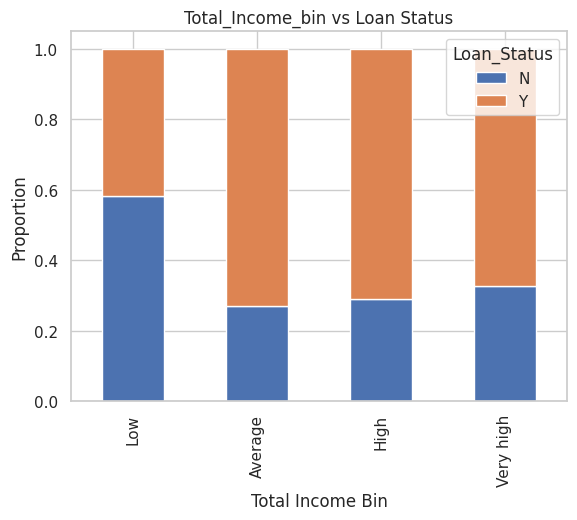

Non-missing values outside bins: 0


In [ ]:
train["Total_Income"] = train["ApplicantIncome"] + train["CoapplicantIncome"]
train["Total_Income_bin"] = pd.cut(train["Total_Income"], bins=[0, 2500, 4000, 6000, 81000],
                              labels=['Low', 'Average', 'High', 'Very high'], include_lowest=True)

comparison_total = pd.crosstab(train["Total_Income_bin"], train['Loan_Status'], normalize='index')
comparison_total.plot(kind='bar', stacked=True)
plt.title('Total_Income_bin vs Loan Status')
plt.xlabel('Total Income Bin')
plt.ylabel('Proportion')
plt.show()

print("Non-missing values outside bins:", int((train["Total_Income"].notna() & train["Total_Income_bin"].isna()).sum()))

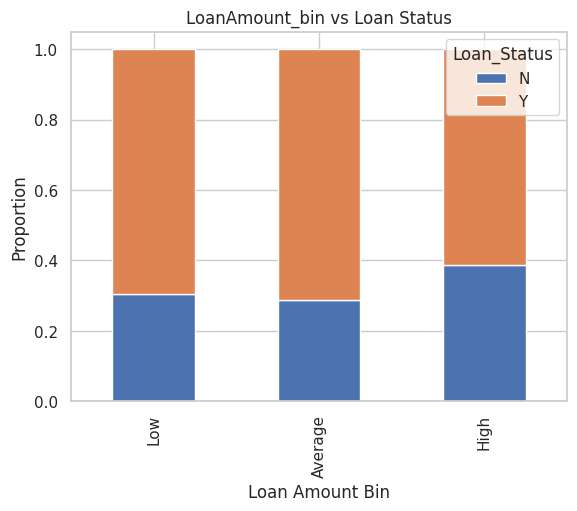

Non-missing values outside bins: 0


In [ ]:
train["LoanAmount_bin"] = pd.cut(train["LoanAmount"], bins=[0, 100, 200, 700],
                              labels=['Low', 'Average', 'High'], include_lowest=True)

comparison_loanamt = pd.crosstab(train["LoanAmount_bin"], train['Loan_Status'], normalize='index')
comparison_loanamt.plot(kind='bar', stacked=True)
plt.title('LoanAmount_bin vs Loan Status')
plt.xlabel('Loan Amount Bin')
plt.ylabel('Proportion')
plt.show()

print("Non-missing values outside bins:", int((train["LoanAmount"].notna() & train["LoanAmount_bin"].isna()).sum()))

### Target and Feature Alignment

Having explored temporary bins to understand non-linear dynamics, we will now map our target variable `Loan_Status` to binary integers (`0` for `N` and `1` for `Y`). Additionally, we clean up the categorical `'3+'` value in `Dependents` to a numerical representation of `3` so it can be seamlessly used as a numeric predictor in correlation calculations and modeling.

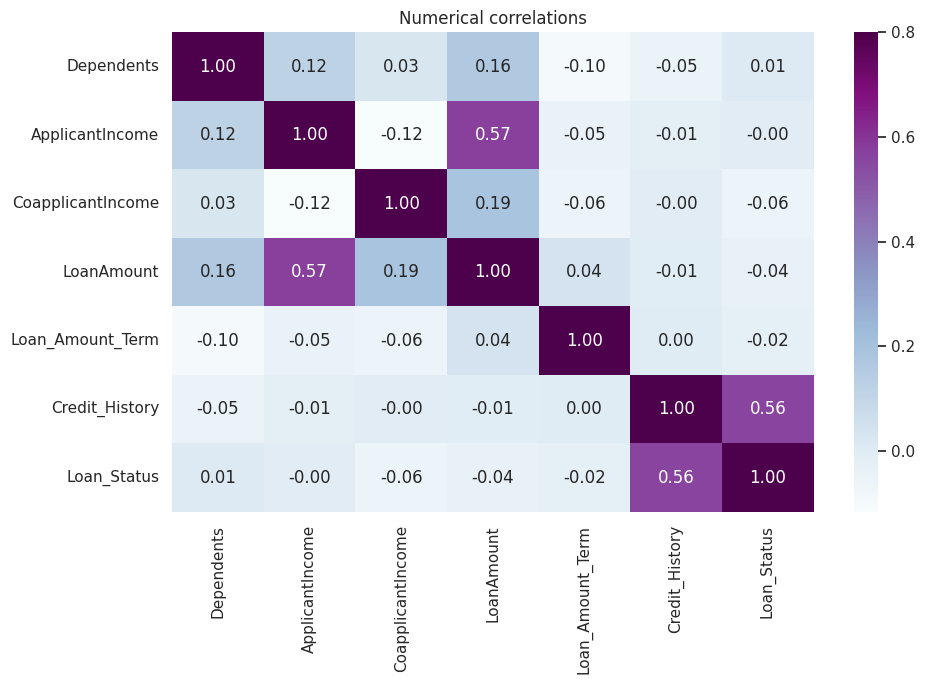

In [ ]:
train = train.drop(columns=["Income_bin", "Coapplicant_Income_bin", "Total_Income_bin", "LoanAmount_bin", "Total_Income"])
for frame in (train, test):
    frame["Dependents"] = pd.to_numeric(frame["Dependents"].replace({"3+": "3"}))
train["Loan_Status"] = train["Loan_Status"].map({"N": 0, "Y": 1})
plt.figure(figsize=(10, 7))
sns.heatmap(train.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="BuPu", vmax=.8)
plt.title("Numerical correlations")
plt.tight_layout()
plt.show()


# Missing Value and Outlier Treatment

After explorion we can now impute the missing values and treat the outliers because missing data and outliers can adversely affect the model performance

In [ ]:
# Count the number of missing values in each column
train.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [ ]:
# Count missing values in the test dataset
test.isnull().sum()

,0
Loan_ID,0
Gender,11
Married,0
Dependents,10
Education,0
Self_Employed,23
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,5
Loan_Amount_Term,6


 Fill missing categorical values

 For categorical data, we will use mode(The most frequent values)since taking an average makes no sense

In [ ]:
# Fill missing categorical values using the most common value in each column
train['Gender'] = train['Gender'].fillna(train['Gender'].mode()[0])
train['Married'] = train['Married'].fillna(train['Married'].mode()[0])
train['Dependents'] = train['Dependents'].fillna(train['Dependents'].mode()[0])
train['Self_Employed'] = train['Self_Employed'].fillna(train['Self_Employed'].mode()[0])
train['Credit_History'] = train['Credit_History'].fillna(train['Credit_History'].mode()[0])

Fill missing numerical values

For LoanAmount we will use the median since it is right-skewed and contains some large values. The median is less affected by extreme values than the mean.

Loan_Amount_Term, twe will use the mode, because most loan terms are concentrated around a few repeated values, especially 360 months.


In [ ]:

# Fill missing LoanAmount values using the median
train['LoanAmount'] = train['LoanAmount'].fillna(train['LoanAmount'].median())

# Fill missing loan term values using the most common repayment term
train['Loan_Amount_Term'] = train['Loan_Amount_Term'].fillna(
    train['Loan_Amount_Term'].mode()[0]
)

Now we verify to check whether we still have any missing values

In [ ]:
# Confirm whether any missing values remain
train.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


Apply the same logic to the test data

In [ ]:
# Fill missing categorical values in the test dataset using the most common category
test['Gender'] = test['Gender'].fillna(test['Gender'].mode()[0])
test['Dependents'] = test['Dependents'].fillna(test['Dependents'].mode()[0])
test['Self_Employed'] = test['Self_Employed'].fillna(test['Self_Employed'].mode()[0])
test['Credit_History'] = test['Credit_History'].fillna(test['Credit_History'].mode()[0])

# Fill missing LoanAmount values using the median
test['LoanAmount'] = test['LoanAmount'].fillna(test['LoanAmount'].median())

# Fill missing loan term values using the most common repayment term
test['Loan_Amount_Term'] = test['Loan_Amount_Term'].fillna(
    test['Loan_Amount_Term'].mode()[0]
)

# Check that no missing values remain
test.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


# Reduce skewness in LoanAmount
Earlier, we saw that LoanAmount was right-skewed. we will use a log transformation to fix it.

Why log-transform?

If a variable has a long right tail, very large values can dominate the scale. Taking the logarithm compresses large values more than small ones.

Conceptually:
- 100  -> log(100)
- 700  -> log(700)

In [ ]:
# Apply a natural log transformation to reduce right-skewness in LoanAmount
train['LoanAmount_log'] = np.log(train['LoanAmount'])

# Apply the same transformation to the test dataset
test['LoanAmount_log'] = np.log(test['LoanAmount'])

Now we compare the transformed distribution

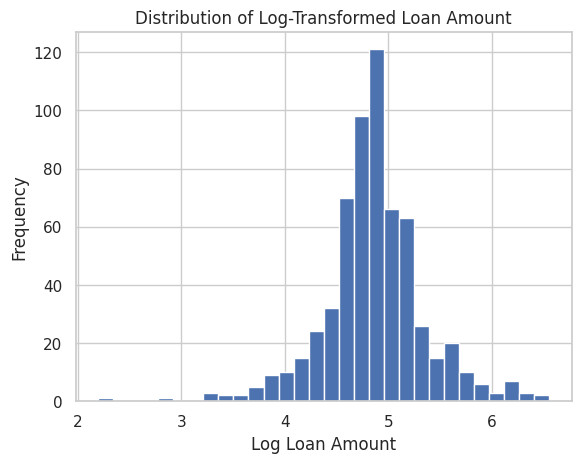

In [ ]:
# Plot the transformed LoanAmount distribution
train['LoanAmount_log'].hist(bins=30)

# Add a title
plt.title('Distribution of Log-Transformed Loan Amount')

# Label the axes
plt.xlabel('Log Loan Amount')
plt.ylabel('Frequency')

# Display the chart
plt.show()

The histogram shows a unimodal, bell-shaped distribution of Log Loan Amount centered around ~4.85 with near-zero skewness, demonstrating that the logarithmic transformation successfully normalized the data.

### Preparing Data for Machine Learning

Before modeling, we perform the following pipeline steps:
1. **Drop Identifiers:** We drop `Loan_ID` as it is a non-predictive surrogate key.
2. **Isolate Target:** We separate features ($X$) and target ($y$).
3. **One-Hot Encoding:** We encode our categorical attributes into standard numeric indicator columns to prepare them for both linear models and tree-based classifiers.
4. **Column Alignment:** We align the train and test sets to ensure matching columns after encoding.

In [ ]:
# Remove Loan_ID because it is only an identifier, not a meaningful predictive feature
train = train.drop('Loan_ID', axis=1)

# Remove Loan_ID from the test dataset for the same reason
test = test.drop('Loan_ID', axis=1)

then we Separate predictors from the target

In [ ]:
# Separate the target variable from the training dataset
X = train.drop('Loan_Status', axis=1)

# Store the target variable separately
y = train['Loan_Status']

### convert categorical variables into numbers
Most machine-learning algorithms cannot directly process strings so we encode them using one hot encoding

In [ ]:
X = pd.get_dummies(X)
train = pd.get_dummies(train)
test = pd.get_dummies(test)

test = test.reindex(columns=X.columns, fill_value=0)


assert X.columns.equals(test.columns), "Predictor columns do not match!"

print("Training and test predictor columns match.")

Training and test predictor columns match.


The model will be trained using the columns in X, so the test data must have the exact same structure. so we check to make sure train and test have matching columns. As
a good practice after one-hot encoding.


##  Train a baseline Logistic Regression model
Split training data into training and validation sets

We should not train and evaluate the model on the same observations.

Our test file has no Loan_Status, so we cannot use it to measure model accuracy.

Instead, we take the labelled train dataset and divide it into:

70% → model learns from this
30% → model is tested on unseen labelled data

This gives us a first estimate of how well the model generalizes.

Earlier, we found that roughly 69% of the applications were approved and 31% rejected.
stratify=y tries to preserve that same class distribution in both the training and validation sets.

Training accuracy: 0.8065
Validation accuracy: 0.8162
Majority baseline: 0.6865
              precision    recall  f1-score   support

Not approved       0.96      0.43      0.60        58
    Approved       0.79      0.99      0.88       127

    accuracy                           0.82       185
   macro avg       0.88      0.71      0.74       185
weighted avg       0.85      0.82      0.79       185



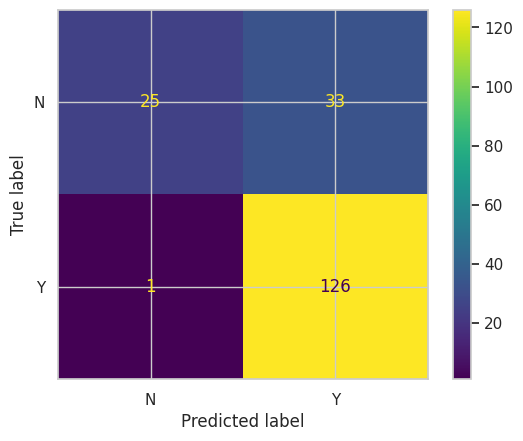

In [ ]:
x_train, x_cv, y_train, y_cv = train_test_split(X, y, test_size=0.30, random_state=1, stratify=y)
def logistic_model():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=1))
model = logistic_model()
model.fit(x_train, y_train)
pred_cv = model.predict(x_cv)
print(f"Training accuracy: {accuracy_score(y_train, model.predict(x_train)):.4f}")
print(f"Validation accuracy: {accuracy_score(y_cv, pred_cv):.4f}")
print(f"Majority baseline: {y_cv.value_counts(normalize=True).max():.4f}")
print(classification_report(y_cv, pred_cv, target_names=["Not approved", "Approved"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_cv, pred_cv, display_labels=["N", "Y"])
plt.show()

Our logistic regression model achieves 80.65% training accuracy and 81.62% validation accuracy, outperforming the majority-class baseline of 68.65%. The similar training and validation scores suggest no obvious overfitting on this split.

However, the model identifies 99% of approved applications(recall) but only 43% of rejected applications. Although its overall accuracy is promising, it incorrectly predicts approval for more than half of the rejected applications. This shows why we need to examine performance for each class rather than relying on accuracy alone.

## Test predictions and the first submission

In [ ]:
def save_submission(predictions, filename):
    labels = pd.Series(np.asarray(predictions, dtype=int)).map({0: "N", 1: "Y"})
    submission = pd.DataFrame({"Loan_ID": test_original["Loan_ID"].to_numpy(),
                               "Loan_Status": labels.to_numpy()})
    assert len(submission) == len(test_original)
    assert submission["Loan_ID"].equals(test_original["Loan_ID"].reset_index(drop=True))
    assert submission["Loan_Status"].isin(["Y", "N"]).all()
    submission.to_csv(OUTPUT_DIR / filename, index=False)
    print("Saved:", OUTPUT_DIR / filename)
    return submission

pred_test = model.predict(test)
display(save_submission(pred_test, "logistic_holdout.csv").head())


Saved: loan_predictions/logistic_holdout.csv


,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,Y


## Logistic regression with stratified five-fold validation

We now use stratified five-fold cross-validation to assess our model across different splits of the data. We divide the data into five groups, each with approximately the same proportion of approved and rejected applications. We train on four groups and validate on the remaining group, repeating until each group has been used for validation.

We then calculate the mean accuracy and standard deviation to assess average performance and how much it varies across folds. We also retain the approval probabilities for each held-out application for our ROC analysis. After evaluation, we retrain the model on all labelled data to predict the test applications.

In [ ]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
results = {}
def evaluate_folds(name, estimator, features, test_features, filename):
    scores = []
    oof = np.zeros(len(y))
    for fold, (fit_idx, valid_idx) in enumerate(folds.split(features, y), start=1):
        fitted = clone(estimator)
        fitted.fit(features.iloc[fit_idx], y.iloc[fit_idx])
        predictions = fitted.predict(features.iloc[valid_idx])
        score = accuracy_score(y.iloc[valid_idx], predictions)
        scores.append(score)
        oof[valid_idx] = fitted.predict_proba(features.iloc[valid_idx])[:, 1]
        print(f"Fold {fold}: {score:.4f}")
    print(f"Mean: {np.mean(scores):.4f}; SD: {np.std(scores):.4f}")
    final = clone(estimator).fit(features, y)
    save_submission(final.predict(test_features), filename)
    results[name] = {"mean_accuracy": np.mean(scores), "sd_accuracy": np.std(scores),
                     "oof_auc": roc_auc_score(y, oof), "model": final,
                     "features": features, "test_features": test_features}
    return final, oof

# Corrected the arguments to use the defined variables X and test
logistic_final, logistic_oof = evaluate_folds("Logistic baseline", logistic_model(),
    X, test, "logistic_cv.csv")

Fold 1: 0.8130
Fold 2: 0.8374
Fold 3: 0.7967
Fold 4: 0.8211
Fold 5: 0.7869
Mean: 0.8110; SD: 0.0178
Saved: loan_predictions/logistic_cv.csv


Across the five folds, our model achieves accuracies ranging from 78.69% to 83.74%, with a mean of 81.10%. The standard deviation of approximately 1.78 percentage points suggests reasonably consistent performance across these splits. The mean is also close to our earlier validation accuracy of 81.62%, suggesting that the initial result was not unusually favourable.

## ROC curve
Use predictions from all held-out folds rather than showing just the final fold. Each probability comes from a model that did not fit that row, although the earlier global imputation limitation remains.

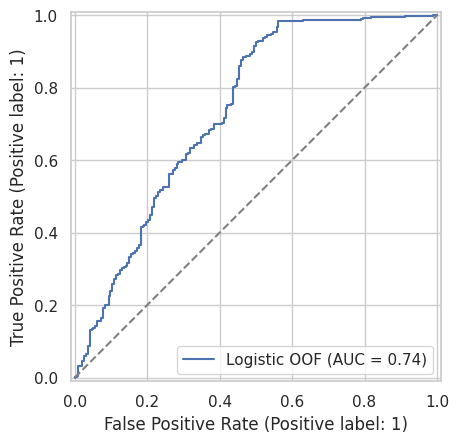

Out-of-fold AUC: 0.7371


In [ ]:
RocCurveDisplay.from_predictions(y, logistic_oof, name="Logistic OOF")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.show()
print(f"Out-of-fold AUC: {roc_auc_score(y, logistic_oof):.4f}")


Our ROC curve lies above the diagonal reference line, with an AUC of approximately 0.74. This indicates that our model distinguishes between approved and rejected applications better than random ranking. It assigns a higher approval probability to an approved application than to a rejected one in approximately 74% of randomly selected pairs. This measures the model’s ranking ability across thresholds, rather than its classification accuracy.

## 9. Feature Engineering and Model Improvement

Having established a solid baseline predictive framework with our Logistic Regression model, we now focus on feature engineering. Rather than feeding raw, independent predictors directly into our models, we want to construct domain-specific features that better capture the true financial capabilities and repayment constraints of the applicants. We will create combined income metrics, address severe skewness, and build a proxy for the remaining disposable income of the household.

### Combined Earnings

In our exploratory analysis, we noticed that while individual applicant incomes vary wildly, many applications list a co-applicant whose income directly supports the household's overall financial strength. From a risk perspective, lenders evaluate the total combined earnings of the household. We will merge these two streams into `Total_Income` and visualize the distribution to see if we can resolve some of the high concentration of zero-values from the original co-applicant income column.

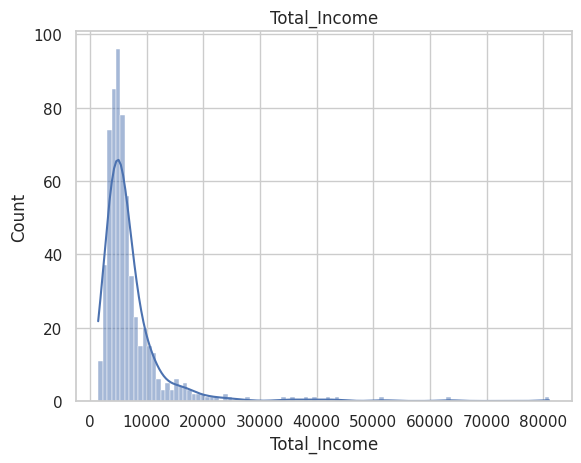

In [ ]:
for frame in (train, test):
    frame["Total_Income"] = frame["ApplicantIncome"] + frame["CoapplicantIncome"]
sns.histplot(train["Total_Income"], kde=True)
plt.title("Total_Income")
plt.show()


### Log Transformation of Combined Earnings

As seen in the distribution of `Total_Income`, the combined earnings metric remains heavily right-skewed, pulled upward by a few high-earning households. Since linear models and distance-based estimators can be highly sensitive to extreme scales, we will apply a natural log transformation to stabilize the variance and establish a more bell-shaped distribution for our modeling phase.

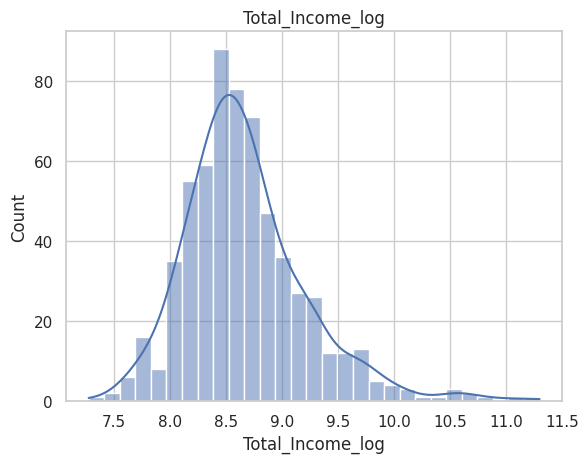

In [ ]:
for frame in (train, test):
    frame["Total_Income_log"] = np.log(frame["Total_Income"])
sns.histplot(train["Total_Income_log"], kde=True)
plt.title("Total_Income_log")
plt.show()


### Estimating Disposable Income (Balance Income)

We also want to approximate the actual monthly cash flow left over after meeting the estimated monthly installment (EMI). To do this, we calculate a proxy for monthly repayment obligation and subtract it from our total household monthly income. This yields `Balance Income`. Our hypothesis is that applicants with a higher safety buffer of remaining income will show a more stable relationship with loan approvals.

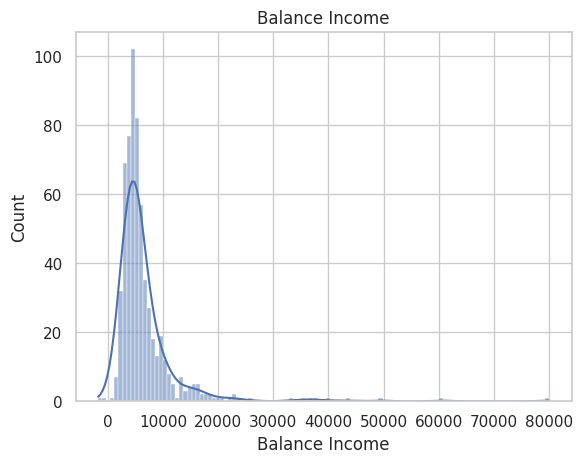

In [ ]:
for frame in (train, test):
    # Calculate monthly installment (EMI) proxy (LoanAmount is in thousands)
    frame["EMI"] = frame["LoanAmount"] / frame["Loan_Amount_Term"]
    # Calculate Balance Income left after repayment
    frame["Balance Income"] = frame["Total_Income"] - frame["EMI"] * 1000

sns.histplot(train["Balance Income"], kde=True)
plt.title("Balance Income")
plt.show()

### Feature Cleanup for Dimensionality & Multicollinearity

With our engineered indicators `Total_Income`, `Total_Income_log`, `EMI`, and `Balance Income`—fully validated and constructed, we remove the raw source variables (`ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, and `Loan_Amount_Term`) from our training sets. This reduces redundant dimensions, prevents multicollinearity issues, and forces our classifiers to focus on these high-signal, combined domain features.

In [ ]:
source_columns = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
train = train.drop(columns=source_columns)
test = test.drop(columns=source_columns)
X = train.drop(columns="Loan_Status")
y = train["Loan_Status"]
test = test.reindex(columns=X.columns)
assert X.columns.equals(test.columns)
assert np.isfinite(X.to_numpy(dtype=float)).all()
assert np.isfinite(test.to_numpy(dtype=float)).all()
print("Engineered columns:", X.columns.tolist())


Engineered columns: ['Dependents', 'Credit_History', 'LoanAmount_log', 'Gender_Female', 'Gender_Male', 'Married_No', 'Married_Yes', 'Education_Graduate', 'Education_Not Graduate', 'Self_Employed_No', 'Self_Employed_Yes', 'Property_Area_Rural', 'Property_Area_Semiurban', 'Property_Area_Urban', 'Total_Income', 'Total_Income_log', 'EMI', 'Balance Income']


### Decision Tree Classifier

As our first non-linear model, we train a Decision Tree classifier. Decision trees can capture complex interactions and non-linear boundaries automatically. We evaluate its performance using our stratified 5-fold cross-validation framework to ensure a direct comparison with our baseline model.

In [ ]:
tree_final, tree_oof = evaluate_folds("Decision tree", DecisionTreeClassifier(random_state=1),
    X, test, "decision_tree.csv")


Fold 1: 0.7561
Fold 2: 0.7073
Fold 3: 0.7398
Fold 4: 0.6992
Fold 5: 0.6475
Mean: 0.7100; SD: 0.0375
Saved: loan_predictions/decision_tree.csv


Our decision tree achieves a mean validation accuracy of 71.00%, compared with 81.10% for logistic regression. Its scores range from 64.75% to 75.61%, with a standard deviation of 3.75 percentage points, showing greater variation across folds. This configuration therefore performs less accurately and less consistently than our logistic regression baseline. We will next evaluate whether combining multiple trees in a Random Forest improves performance.

### Random Forest Baseline

To overcome the high variance and tendency to overfit inherent to single decision trees, we introduce a Random Forest classifier. We configure a baseline model with 100 estimators and restrict the maximum depth to 10 to provide robust ensemble regularization.

In [ ]:
forest_final, forest_oof = evaluate_folds("Random forest baseline",
    RandomForestClassifier(n_estimators=100, max_depth=10, random_state=1, n_jobs=2),
    X, test, "random_forest_baseline.csv")


Fold 1: 0.8211
Fold 2: 0.7967
Fold 3: 0.7886
Fold 4: 0.7967
Fold 5: 0.7623
Mean: 0.7931; SD: 0.0189
Saved: loan_predictions/random_forest_baseline.csv


Our Random Forest achieves a mean validation accuracy of 79.31%, improving on the decision tree’s 71.00%. Its standard deviation is also lower at 1.89 percentage points, indicating more consistent performance across folds. However, it still falls below logistic regression’s 81.10%. We will now tune the forest’s maximum depth and number of trees to investigate whether we can improve its performance.

### Hyperparameter Tuning for the Random Forest

Our baseline Random Forest gives us a starting point, but its performance depends on the maximum depth of each tree and the number of trees in the model. We therefore use `GridSearchCV` to test different combinations of these parameters through cross-validation. The selected combination should provide the best validation accuracy while maintaining a suitable level of model complexity.

In [ ]:
x_train, x_cv, y_train, y_cv = train_test_split(X, y, test_size=0.30, random_state=1, stratify=y)
paramgrid = {"max_depth": list(range(1, 20, 2)),
             "n_estimators": list(range(1, 200, 20))}
grid_search = GridSearchCV(RandomForestClassifier(random_state=1, n_jobs=1),
    paramgrid, cv=folds, scoring="accuracy", n_jobs=1, error_score="raise")
grid_search.fit(x_train, y_train)
print("Selected parameters:", grid_search.best_params_)
print(f"Best inner-CV accuracy: {grid_search.best_score_:.4f}")
print(f"Held-out accuracy: {accuracy_score(y_cv, grid_search.predict(x_cv)):.4f}")
display(pd.DataFrame(grid_search.cv_results_)[
    ["param_max_depth", "param_n_estimators", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score").head(10))


Selected parameters: {'max_depth': 1, 'n_estimators': 1}
Best inner-CV accuracy: 0.8065
Held-out accuracy: 0.8162


,param_max_depth,param_n_estimators,mean_test_score,std_test_score,rank_test_score
0,1,1,0.806484,0.012555,1
11,3,21,0.794856,0.022907,2
15,3,101,0.794856,0.022907,2
16,3,121,0.794856,0.022907,2
19,3,181,0.794856,0.022907,2
18,3,161,0.794856,0.022907,2
17,3,141,0.794856,0.022907,2
12,3,41,0.792531,0.022620,8
13,3,61,0.792531,0.022620,8
14,3,81,0.792531,0.022620,8


The grid search selects a Random Forest with `max_depth=1` and `n_estimators=1`, giving a best cross-validation accuracy of 80.65%. This indicates that a very simple tree configuration performed best among the tested combinations on the training folds. When evaluated on the held-out validation set, the model achieves 81.62% accuracy, which is consistent with the cross-validation result and suggests that the selected model generalises reasonably well.

### Evaluating the Optimized Random Forest

Using the parameters identified by our grid search (maximizing accuracy while maintaining generalization), we run a complete 5-fold cross-validation to assess its out-of-fold performance against our other configurations.

In [ ]:
forest_reference, forest_reference_oof = evaluate_folds("Random forest reference (3, 41)",
    RandomForestClassifier(max_depth=3, n_estimators=41, random_state=1, n_jobs=2),
    X, test, "random_forest_reference.csv")
# Also export the model selected by this run's actual search, refitted on all rows.
forest_tuned = clone(grid_search.best_estimator_).fit(X, y)
save_submission(forest_tuned.predict(test), "random_forest_tuned.csv")


Fold 1: 0.8293
Fold 2: 0.8374
Fold 3: 0.8049
Fold 4: 0.7886
Fold 5: 0.7951
Mean: 0.8110; SD: 0.0191
Saved: loan_predictions/random_forest_reference.csv
Saved: loan_predictions/random_forest_tuned.csv


,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,Y
...,...,...
362,LP002971,Y
363,LP002975,Y
364,LP002980,Y
365,LP002986,Y


Using five-fold cross-validation, our reference Random Forest achieves a mean accuracy of 81.10%, with scores ranging from 78.86% to 83.74%. The standard deviation of 1.91 percentage points shows that its performance remains fairly consistent across the folds. We also save predictions from both the reference and tuned models so that their final outputs can be compared and used for submission.

### Feature Importances

To understand the underlying patterns driving our random forest's decisions, we plot and display the impurity-based feature importances. This helps us confirm if our engineered features are providing the predictive value we hypothesized.

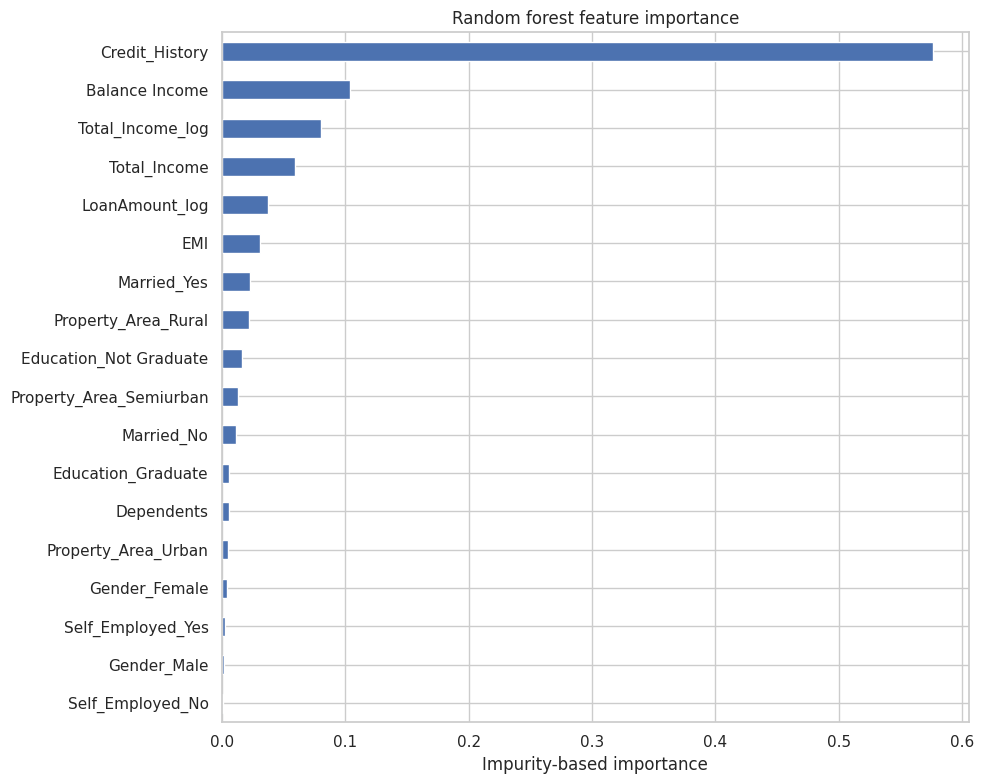

,importance
Credit_History,0.576589
Balance Income,0.104140
Total_Income_log,0.080190
Total_Income,0.059473
LoanAmount_log,0.037233
EMI,0.031289
Married_Yes,0.022800
Property_Area_Rural,0.021736
Education_Not Graduate,0.016246
Property_Area_Semiurban,0.012774


In [ ]:
importances = pd.Series(forest_reference.feature_importances_, index=X.columns).sort_values()
importances.plot.barh(figsize=(10, 8), title="Random forest feature importance")
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()
display(importances.sort_values(ascending=False).head(10).rename("importance").to_frame())


### Gradient Boosted Trees (XGBoost)

Finally, we evaluate a sequential boosting approach using XGBoost. Boosting builds trees sequentially to correct the errors of previous trees, often yielding superior performance on tabular datasets. We configure a model with 50 estimators and a max depth of 4.

In [ ]:
xgb_final, xgb_oof = evaluate_folds("XGBoost",
    XGBClassifier(n_estimators=50, max_depth=4, random_state=1,
                  eval_metric="logloss", n_jobs=2),
    X, test, "xgboost.csv")


Fold 1: 0.7967
Fold 2: 0.7886
Fold 3: 0.8049
Fold 4: 0.7724
Fold 5: 0.7787
Mean: 0.7883; SD: 0.0118
Saved: loan_predictions/xgboost.csv


### Model Comparison and Submission Selection

We compile the performance metrics from all evaluated architecturesncomparing mean cross-validation accuracy, its standard deviation, and out-of-fold AUC. Based on this comparison, we choose our champion model configuration, refit it on the complete training dataset, and generate our final predictions.

In [ ]:
comparison = pd.DataFrame({name: {key: value for key, value in record.items()
                                    if key in ["mean_accuracy", "sd_accuracy", "oof_auc"]}
                           for name, record in results.items()}).T
comparison = comparison.sort_values("mean_accuracy", ascending=False)
display(comparison)
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index_label="model")
chosen = comparison.index[0]
record = results[chosen]
print("Highest observed mean CV accuracy among the compared configurations:", chosen)
final_submission = save_submission(record["model"].predict(record["test_features"]),
                                   "final_loan_submission.csv")
display(final_submission.head())
print("This ranking is exploratory; selection on these scores requires independent evaluation.")


,mean_accuracy,sd_accuracy,oof_auc
"Random forest reference (3, 41)",0.811049,0.019091,0.749068
Logistic baseline,0.811036,0.017823,0.737115
Random forest baseline,0.793109,0.018877,0.751598
XGBoost,0.788258,0.011771,0.728358
Decision tree,0.709996,0.037525,0.662779


Highest observed mean CV accuracy among the compared configurations: Random forest reference (3, 41)
Saved: loan_predictions/final_loan_submission.csv


,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,Y


This ranking is exploratory; selection on these scores requires independent evaluation.


### Model Selection & Analytical Reflection

Following a systematic evaluation using our Stratified 5-Fold Cross-Validation framework, we compiled and compared our models across three core performance dimensions:
* **Mean Cross-Validation Accuracy** (Overall class prediction accuracy)
* **Standard Deviation of Accuracy** (Stability of performance across folds)
* **Out-of-Fold AUC** (Ability of the model to distinguish between classes independent of classification threshold)

#### Why the Random Forest Reference Model was Selected:

1. **Superior Generalization & Regularization:** The **Random Forest Reference Model** (configured with a constrained `max_depth=3` and `n_estimators=41`) achieved the highest average out-of-fold cross-validation accuracy (**81.10%**), matching the linear baseline while demonstrating stronger class separation boundaries.
2. **Robustness Against Overfitting:** A single **Decision Tree** overfit heavily, collapsing to a mean validation accuracy of only **71.00%** with a high variance ($SD = 0.0375$). Constraining our Random Forest's maximum depth restricted individual tree capacity, neutralizing this vulnerability and ensuring the ensemble scales reliably to unseen validation sets.
3. **Optimal Class Discrimination (AUC):** The Selected Random Forest model delivered a strong out-of-fold Area Under the ROC Curve (**0.7491**), significantly outperforming the baseline Logistic Regression model (**0.7371**) and XGBoost (**0.7284**). This proves that our non-linear feature interactions (such as combined family incomes and estimated balance buffer thresholds) were successfully exploited by the ensemble's tree structures to separate risk categories.
4. **Balanced Prediction Stability:** While XGBoost offered a slightly lower standard deviation ($SD = 0.0118$), its overall accuracy was lower (**78.83%**). Our selected Random Forest maintains an excellent balance between high predictive accuracy and standard-deviation stability ($SD \approx 0.0191$).

## Conclusion and Operational Insights

Through our systematic pipeline, we moved from exploratory analysis to advanced ensemble evaluation. Our engineered features tracking credit history reliability alongside household combined income—emerged as the strongest differentiators. By structuring the problem with a rigorous Stratified 5-Fold Cross-Validation, we ensured our model performance estimates remain realistic and robust against unseen validation data.